# Cost Curve Creator

This notebook enables fitting curves to ORBIT models to create a cost function that can be
embedded in [NRWAL](https://github.com/NatLabRockies/NRWAL). A variety of curve and surface
fitting options are available, and new ones can be added easily. There are also tools for
visualizing the ORBIT data and fitted curves.

## Extra Optional Dependencies

- `ipympl` (`pip install ipympl`) enables interactive matplotlib elements in Jupyter notebooks via
  the `%matplotlib widget` magic command below

## Instructions

Follow the steps below to configure and run the notebook.

1. Create a basic ORBIT configuration file including at least the following sections. As a note,
   this example makes use of the
   [`narwal.yaml`](https://github.com/NLRWindSystems/ORBIT/tree/main/examples/configs/narwal.yaml)
   configuration file.
* site
* turbine
* plant

2. Configure the notebook by setting the following variables in the
   [Configuration](#configuration) section:
* `BASE_CONFIG`: the ORBIT config file at a given path
* `DEPTHS`: a list of water depths to use for cost curves
* `MEAN_WIND_SPEED`: a list of mean wind speed to use for cost curves
* Add any additional global parameter ranges

3. Run the notebook to establish a first-pass fit for the ORBIT data. This will also plot the ORBIT
data and curves.

4. Refine the curve fits by swapping the curve-fit function from the options available in
the "Curve Fit Library" section

## Practical Guidance

This notebook specifically models spatially varying costs typically related to water depth but in
some cases other variables are considered. The same methods could be used to model the cost
relationship for other variables. The general workflow is to first create a parameterized ORBIT
model and obtain the cost as a function of the variables of interest. Then, fit a curve or surface
to the data by starting with the linear options. Plot the data and curve fits to evaluate whether
the linear forms are sufficient. If not, move to the quadratic or higher order curve fits.

A class `CostFunction` is provided to simplify running the ORBIT parameterization, fit the
curves to the data, and visualize the results. An example is given below to instantiate the
class:

```python
cost_function = CostFunction(
    config={"design_phases": ["MonopileDesign"]},
    parameters={
        "site.depth": DEPTHS,
        "site.mean_windspeed": MEAN_WIND_SPEED,
    },
    results={
        "monopile_unit_cost": lambda run: run.design_results["monopile"]["unit_cost"],
    }
)
```

The `config` parameter is a dictionary containing additional configuration parameters to add to
the base ORBIT configuration provided through the input file created in Step 1 in the instructions.
Any parameters given in the `CostFunction` `config` will be added to the base configuration or
overwritten if they already exist.

The `parameters` dictionary contains the variables to be varied in the cost function via
ORBIT's `ParametricManager`, and the `results` dictionary sets the results variables from ORBIT.
Each of these dictionaries are passed directly to the `ParametricManager` class.

The fitted curves are saved on the `CostFunction` object and multiple types can exist at the
same time. Two versions of one type cannot be saved at the same time. To create a curve fit,
call one of the curve fit methods on the `CostFunction` instance. Then, an attribute is saved
on the instance with the curve fit type.

Considerations:
- The `CostFunction` class supports parameterizations of at-most 2 variables.
- One instance of the `CostFunction` class can be used to fit multiple curves for a single
    cost model.
- A new `CostFunction` instance should be created for each cost model.

### Plotting API for 2D vs 3D plots

The `CostFunction` class handles 2D and 3D data seamlessly by using the x and z parameters for 2D
and adding y for 3D. The appropriate matplotlib API is used depending if the data is 2D or 3D.
From the calling script, be sure to configure the Axes that is given to `CostFunction.plot` with
the correct settings for 3D as listed in the table below.

| Matplotlib setting | 2D | 3D |
|---------------------|----|----|
| Independent axis labels | `ax.set_xlabel()`  | `ax.set_xlabel()`, `ax.set_zlabel()` |
| Dependent axis label | `ax.set_ylabel()` | `ax.set_zlabel()` |

### Template workflow

The following code block provides a template for creating a cost function for a model with
two independent parameters.

```python
# 1. Create the CostFunction object with the ORBIT configuration for the parameterization
cost_function = CostFunction(
    config={
        "design_phases": ["Design"],
    },
    parameters={
        "site.depth": DEPTHS,
        "site.mean_windspeed": MEAN_WIND_SPEED,
    },
    results={
        "system_cost": lambda run: run.design_results["system"]["system_cost"],
    }
)

# 2. Run ORBIT via ORBIT.ParametricManager
cost_function.run()

# 3. Fit two curves (surfaces since there are two independent parameters) to the data.
# After running the following two commands, the CostFunction object will have two related
# attributes that store the curve fits.
cost_function.fit_curve("linear_2d")
cost_function.fit_curve("quadratic_2d")

# 4. Plot the data and curves
fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
ax.set_title("Depth vs mean wind speed")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Mean wind speed (m/s)")
ax.set_zlabel("Cost ($)")
cost_function.plot(ax, plot_data=True)
cost_function.plot(ax, plot_curves=["linear_2d", "quadratic_2d"])   # These curves must have been generated first
# alternatively, the two lines above could be combined into a single line:
# cost_function.plot(ax, plot_data=True, plot_curves=["linear_1d", "quadratic_1d"])

# 5. Export the curve function to a NRWAL-compatible file
cost_function.export("design.yaml", "design_system")
```

### Adding a new curve type

There are a number of curve fit options in the `CostFunction` class, and more can be added by
creating a new method and connecting it in some key places in the class.

First, create a new method on the `CostFunction` class that follows the naming convention of
`{curve_type}_{dimension}` where `curve_type` is the name of the type of function like "exponential"
or "linear" and `dimension` is the number of independent variables the curve. The function should
return the fit curve evaluated at the data points given to fit the curve. A generic function
signature is given below:

```python
class CostFunction:

    def curvetype_dimension(self):
        ...

    def linear_1d(self):
        ...
```

To fit a curve to the data for one independent variable, it is recommended to use the
`scipy.optimize.curve_fit` function via the `Curves` class. In general, a one-dimensional curve fit
function will follow the form given below. By setting the curve fit function `f`, you define the
shape of the curve and set the order of the coefficients in `self.coeffs` since they are returned in
the order they are given in the function signature. The `Curves.polynomal_eval` function is
available to easily evaluate polynomial curves, but other curve-types can be evaluated by simply
plugging in the data points (`self.x`) to the fit function.

```python
# Define a function for a prototype curve; this is where you define the shape of the curve
def f(x, a, b):
    return a * x + b

# Call the scipy.optimize.curve_fit function and get the coefficients as a Numpy array
# Note that `self.x` and `self.z` are given since the CostFunction class adds a y
# only when there are more independent variables.
self.coeffs = Curves.fit(f, self.x, self.z)

# Evaluate the curve at the data points (self.x)
self._linear_1d_curve = Curves.polynomial_eval(self.coeffs, self.x)
```

A two-dimensional curve (surface) fit will typically follow a similar process, as shown below. For
these types, it is recommended to use the `numpy.linalg.lstsq` function. First, reshape the data
into a new array with each element containing the three-dimensional data points. Then, stack the
data into a column matrix in the form of the equation that you're implementing. See the comments in
the code block for more information. Evaluate the curve at the data points (`self.x`, `self.y`) by
stating the form of the curve with the coefficients from the curve fit.

```python
    ...

    # Reshape the data into a new array where each element is a three-dimensional data point
    data_to_fit = np.array(list(zip(self.x, self.y, self.z, strict=True)))

    # Stack the data into a column matrix in the form of the equation that you're
    # implementing. Here, the equation is z = ax + by + c and data_to_fit[:,0] are the x
    # values, data_to_fit[:,1] are the y values. The third column is all ones to account
    # for the constant term.
    A = np.c_[
        data_to_fit[:,0],
        data_to_fit[:,1],
        np.ones(data_to_fit.shape[0])
    ]

    # Fit the curve to the data; the data is the cost and these are always
    # self.z which is data_to_fit[:,2]
    self.coeffs, _, _, _ = linalg.lstsq(A, data_to_fit[:, 2])

    # Evaluate it on the same points as the input data
    self._linear_2d_curve = self.coeffs[0]*self.x + self.coeffs[1]*self.y + self.coeffs[2]
```

Finally, save the coefficients to `self.coeffs`, save the evaluated curve to
`self._{curve_type}_{dimension}_curve`, and add the corresponding if-statements
in `CostFunction.plot` and `CostFunction.export`.

## Setup the Example

First, we must import all the required libraries and ORBIT functionality to implement
everything discussed up to this section.

In [1]:
# NOTE: uncomment this line if using the interactive plotting functionality
# %matplotlib widget

from copy import deepcopy
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import optimize, linalg

from ORBIT import ParametricManager, load_config


mpl.rcParams["figure.autolayout"] = True

# Ensure the correct examples directory is used when running this in docs or in examples
here = Path().resolve()
match here.stem:
    case "examples":
        example_dir = here
    case "topical_guides":
        example_dir = here.parents[1] / "examples"
    case "ORBIT":
        example_dir = here / "examples"
    case _:
        msg = "Please manually change `example_dir` if running in a custom location."
        raise FileNotFoundError(msg)

## Configuration

Replace any of these throughout the notebook to customize a cost model parameterization.

In [2]:
BASE_CONFIG = load_config(example_dir / "configs/nrwal.yaml")

DEPTHS = list(range(5, 60, 5))  # Ocean depth in meters
MEAN_WIND_SPEED = list(range(2, 20, 2))  # Mean wind speed in m/s

In [3]:
orbit_to_nrwal_params = {
    "site.depth": "depth",
    "site.mean_windspeed": "mean_windspeed",  # Not in NRWAL
    "site.distance_to_landfall": "dist_s_to_l",
    "mooring_system_design.draft_depth": "draft_depth",  # Not in NRWAL
    "array_system_design.touchdown_distance": "touchdown_distance",  # Not in NRWAL
    "array_system_design.floating_cable_depth": "floating_cable_depth",  # Not in NRWAL
}

## Curve Fit Library

In [4]:
class Curves:
    """
    Provides static methods for fitting data to various curve types.
    Though they could exist outside of a class, consolidating them into a consistent
    namespace allows for a simpler API throughout the script.
    """

    @staticmethod
    def polynomial_eval(coeffs, data_points):
        """
        Evaluates a curve defined by a polynomial equation given a set of
        coefficients and data points.

        Parameters
        ----------
        coeffs : list
            A list of coefficients for the curve. The order of the coefficients should
            be from highest to lowest power.
        data_points : list
            A list of data points at which to evaluate the curve.

        Returns
        -------
        np.array
            The curve evaluated at the given data points.
        """
        curve = np.zeros_like(data_points)
        for i, dp in enumerate(data_points):
            # This loop sums the terms of the polynomial
            for j in range(len(coeffs)):
                curve[i] += coeffs[j] * (dp ** (len(coeffs) - 1 - j))
        return curve

    @staticmethod
    def fit(func, x, y, fit_check=False):
        if isinstance(x, pd.Series):
            x = x.to_numpy(dtype=np.float64)
        elif isinstance(x, np.array):
            x = x.astype(np.float64)
        else:
            raise ValueError("`x` must be a pd.Series or np.ndarray.")

        if isinstance(y, pd.Series):
            y = y.to_numpy(dtype=np.float64)
        elif isinstance(y, np.array):
            y = y.astype(np.float64)
            x = x.astype(np.float64)
        else:
            raise ValueError("`y` must be a pd.Series or np.ndarray.")

        popt, pcov, nfodict, mesg, ier = optimize.curve_fit(
            func, x, y, full_output=True
        )

        if fit_check:
            print(f"message: {mesg}")
            print(f"ier: {ier}")
            print(f"Coefficients: {popt}")
            # print(f"R-squared: {rvalue**2:.6f}")

        return popt

In [5]:
class CostFunction:
    """
    Creates the ORBIT parameterization, curve fits, plots the curve, and exports
    the function to a NRWAL format. Parameterizations are limited to up to two
    independent variables.
    """

    def __init__(self, config: dict, parameters: dict, results: dict):
        """
        Prepares the ``config``, ``parameters``, and ``results`` dictionaries for use
        in ``ParametricManager``. Additionally, the independent variables are extracted
        into ``x` and ``y`` (for two-variable parameterizations) and ``z`` is extracted
        as the dependent variable. Whether the cost function is 3D or 2D is determined
        by the length of the parameters variable.

        Parameters
        ----------
        config : str
            Configuration settings to added to the BASE_CONFIG or overwrite
            in the ``BASE_CONFIG``. This must include the ``design_phases`` config.
        parameters : dict
            Parameters to use with ``ParametricManager``; maximum of two parameters.
        results : dict
            Results to use with ``ParametricManager``; this must include only one variable.
        """
        self.is_3d = False

        # Other attributes
        # self.parametric
        # self.x
        # self.y
        # self.z
        # self.x_variable
        # self.y_variable
        self._linear_1d_curve = None
        self._quadratic_1d_curve = None
        self._poly3_1d_curve = None
        self._linear_2d_curve = None
        self._quadratic_2d_curve = None

        # Start with a copy of the global BASE_CONFIG and update it with the configuration
        # given to this class
        self.config = deepcopy(BASE_CONFIG)
        self.config.update(config)

        self.parameters = deepcopy(parameters)
        if len(self.parameters) > 2:
            raise ValueError(
                "This class is limited to parameterizations with two variables."
            )

        # Puts the parameters and results settings into variables for use in parsing the ORBIT
        # results and postprocessing the data
        self.parameters = deepcopy(self.parameters)
        _vars = list(self.parameters.keys())

        # NOTE: This assumes the first parameter is site.depth; it's not critical to
        # functionality but good to keep in mind
        self.x_variable = _vars.pop(0)

        if len(_vars) == 1:
            self.is_3d = True
            self.y_variable = _vars.pop()
        self.z_variable = list(results.keys())[0]

        self.results = deepcopy(results)
        if len(results) != 1:
            raise ValueError(
                "This class is limited to results with one variable"
            )

    def run(self):
        self.parametric = ParametricManager(
            self.config, self.parameters, self.results, product=True
        )
        self.parametric.run()

        self.x = self.parametric.results[self.x_variable]
        if self.is_3d:
            self.y = self.parametric.results[self.y_variable]
        self.z = self.parametric.results[self.z_variable]

    # -------------------
    # Curve fit functions
    # -------------------

    def linear_1d(self):
        def f(x, a, b):
            return a * x + b

        self.coeffs = Curves.fit(f, self.x, self.z)
        self._linear_1d_curve = Curves.polynomial_eval(self.coeffs, self.x)

    def quadratic_1d(self):
        def f(x, a, b, c):
            return a * x**2 + b * x + c

        self.coeffs = Curves.fit(f, self.x, self.z)
        self._quadratic_1d_curve = Curves.polynomial_eval(self.coeffs, self.x)

    def poly3_1d(self):
        def f(x, a, b, c, d):
            return a * x**3 + b * x**2 + c * x + d

        self.coeffs = Curves.fit(f, self.x, self.z)
        self._poly3_1d_curve = Curves.polynomial_eval(self.coeffs, self.x)

    # def logarithmic_1d(self):
    #     pass

    # def exponential_1d(self):
    #     pass

    def linear_2d(self):
        data_to_fit = np.array(list(zip(self.x, self.y, self.z, strict=True)))

        # Best-fit linear plane
        A = np.c_[
            data_to_fit[:, 0], data_to_fit[:, 1], np.ones(data_to_fit.shape[0])
        ]
        self.coeffs, _, _, _ = linalg.lstsq(
            A, data_to_fit[:, 2]
        )  # coefficients

        # Evaluate it on the same points as the input data
        self._linear_2d_curve = (
            self.coeffs[0] * self.x + self.coeffs[1] * self.y + self.coeffs[2]
        )

    def quadratic_2d(self):
        data_to_fit = np.array(list(zip(self.x, self.y, self.z, strict=True)))

        # best-fit quadratic curve
        A = np.c_[
            np.ones(data_to_fit.shape[0]),
            data_to_fit[:, :2],
            np.prod(data_to_fit[:, :2], axis=1),
            data_to_fit[:, :2] ** 2,
        ]
        self.coeffs, _, _, _ = linalg.lstsq(A, data_to_fit[:, 2])

        # Evaluate it on the same points as the input data
        # This dot product is equivalent to the sum of the terms of the polynomial;
        # np.c_[] is used to concatenate the arrays into the correct form for the
        # dot product and C is the coefficients of the polynomial
        self._quadratic_2d_curve = np.dot(
            np.c_[
                np.ones(self.x.shape),
                self.x,
                self.y,
                self.x * self.y,
                self.x**2,
                self.y**2,
            ],
            self.coeffs,
        ).reshape(self.x.shape)

    # ------------------
    # Plotting functions
    # ------------------

    def plot(
        self,
        ax,
        plot_data: bool = False,
        plot_curves: list[str] = None,
    ):
        if plot_data:
            if self.is_3d:
                ax.scatter(self.x, self.y, zs=self.z, zdir="z", label="Data")
            else:
                ax.scatter(self.x, self.z, label="Data")

        if plot_curves is None:
            plot_curves = []
        for curve in plot_curves:
            match curve:
                case "linear_1d":
                    ax.plot(self.x, self._linear_1d_curve, label="Linear Fit")
                case "quadratic_1d":
                    ax.plot(
                        self.x, self._quadratic_1d_curve, label="Quadratic Fit"
                    )
                case "poly3_1d":
                    ax.plot(
                        self.x,
                        self._poly3_1d_curve,
                        label="Degree 3 Polynomial Fit",
                    )
                case "linear_2d":
                    ax.plot_surface(
                        np.reshape(self.x, (len(DEPTHS), -1)),
                        np.reshape(self.y, (len(DEPTHS), -1)),
                        np.reshape(self._linear_2d_curve, (len(DEPTHS), -1)),
                        alpha=0.3,
                        label="Linear Fit",
                    )
                case "quadratic_2d":
                    ax.plot_surface(
                        np.reshape(self.x, (len(DEPTHS), -1)),
                        np.reshape(self.y, (len(DEPTHS), -1)),
                        np.reshape(
                            self._quadratic_2d_curve, (len(DEPTHS), -1)
                        ),
                        alpha=0.3,
                        label="Quadratic Fit",
                    )

    # ------------------
    # Export functions
    # ------------------

    def export(self, filename: Path, key: str, comments: str = "") -> None:
        """
        Writes the curve equation to a file for use in NRWAL.

        Parameters
        ----------
        filename : Path
            The file to write the curve equation to. If the file exists, the
            equation is appended to the end of the file.
        key : str
            The key to use in the NRWAL file for the curve equation. In the key-value
            pair, this argument is the key and the value is the equation string.
        """

        x_var = orbit_to_nrwal_params[self.x_variable]
        if self.is_3d:
            y_var = orbit_to_nrwal_params[self.y_variable]

        F = "{:.1f}"
        S = "{:s}"
        if self._linear_1d_curve is not None:
            # y = ax + b
            equation_string = f"{F} * {S} + {F}".format(
                self.coeffs[0], x_var, self.coeffs[1]
            )
            equation_string = f"{F} * {S} + {F}".format(
                self.coeffs[0], x_var, self.coeffs[1]
            )

        if self._quadratic_1d_curve is not None:
            # y = ax^2 + bx + c
            equation_string = f"{F} * {S}**2 + {F} * {S} + {F}".format(
                self.coeffs[0], x_var, self.coeffs[1], x_var, self.coeffs[2]
            )

        if self._poly3_1d_curve is not None:
            # y = ax^3 + bx^2 + cx + d
            equation_string = (
                f"{F} * {S}**3 + {F} * {S}**2 + {F} * {S} + {F}".format(
                    self.coeffs[0],
                    x_var,
                    self.coeffs[1],
                    x_var,
                    self.coeffs[2],
                    x_var,
                    self.coeffs[3],
                )
            )

        if self._linear_2d_curve is not None:
            # z = ax + by + c
            equation_string = f"{F} * {S} + {F} * {S} + {F}".format(
                self.coeffs[0], x_var, self.coeffs[1], y_var, self.coeffs[2]
            )

        if self._quadratic_2d_curve is not None:
            # z = ax^2 + bxy + cy^2 + dx + ey + f
            equation_string = (
                f"{F} * {S}**2"
                f" + {F} * {S} * {S}"
                f" + {F} * {S}**2"
                f" + {F} * {S}"
                f" + {F} * {S}"
                f" + {F}".format(
                    self.coeffs[0],
                    x_var,
                    self.coeffs[1],
                    x_var,
                    y_var,
                    self.coeffs[2],
                    y_var,
                    self.coeffs[3],
                    x_var,
                    self.coeffs[4],
                    y_var,
                    self.coeffs[5],
                )
            )

        # nrwal_dict = {self.config["design_phases"][0]: equation_string}
        nrwal_dict = {key: equation_string}

        if isinstance(filename, str):
            filename = Path(filename).resolve()
        with filename.open("a") as f:
            f.write("\n")
            if comments:
                f.write(f"# {comments}\n")
            # f.write(f"# {self.config['design_phases'][0]}\n")
            yaml.dump(nrwal_dict, f)
            f.write("\n")
            print(nrwal_dict)

# ORBIT Design Phase Cost Curves

## Monopile Substructure

Independent variables:
- Water depth: impacts the mass of the monopile since it is fixed to the ocean floor
- Mean wind speed: impact the mass of the monopile by the load transferred from the turbine

ORBIT library intialized at '/Users/rhammond/GitHub/Public/ORBIT/library'
{'substructure_15MW': '-620854.4 * depth**2 + 8899.8 * depth * mean_windspeed + 508191.7 * mean_windspeed**2 + 6938.1 * depth + 247.7 * mean_windspeed + -14812.4'}


{'substructure_15MW': '-620854.4 * depth**2 + 8899.8 * depth * mean_windspeed + 508191.7 * mean_windspeed**2 + 6938.1 * depth + 247.7 * mean_windspeed + -14812.4'}


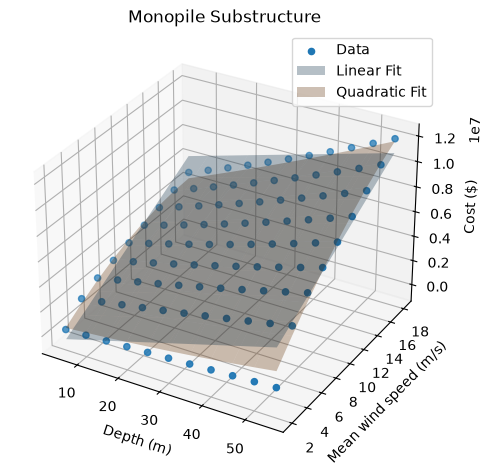

In [6]:
cost_function = CostFunction(
    config={"design_phases": ["MonopileDesign"]},
    parameters={
        "site.depth": DEPTHS,
        "site.mean_windspeed": MEAN_WIND_SPEED,
    },
    results={
        "monopile_unit_cost": lambda run: run.design_results["monopile"][
            "unit_cost"
        ],
        # "transition_piece_unit_cost": lambda run: run.design_results["transition_piece"]["unit_cost"],
    },
)
cost_function.run()

cost_function.linear_2d()
cost_function.quadratic_2d()

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.set_title("Monopile Substructure")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Mean wind speed (m/s)")
ax.set_zlabel("Cost ($)")
cost_function.plot(ax, plot_data=True)
cost_function.plot(ax, plot_curves=["linear_2d", "quadratic_2d"])
ax.legend()

cost_function.export(
    example_dir / "configs/substructure.yaml", "substructure_15MW"
)

## Semi-Submersible Substructure

Since the semisubmersible is a floating structure, the water depth does not impact the mass
of the structure.
The mean wind speed does impact the mass of the structure by the load transferred from the
turbine, but this is not included in the design phase cost model directly.
The plot here shows that the cost is constant with respect to the water depth.

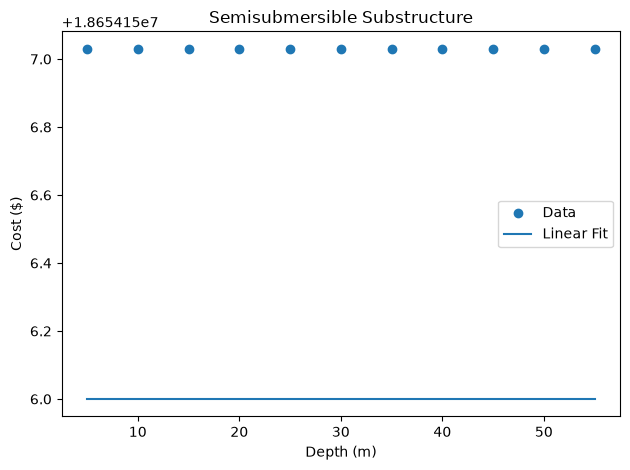

In [7]:
cost_function = CostFunction(
    config={"design_phases": ["SemiSubmersibleDesign"]},
    parameters={
        "site.depth": DEPTHS,
    },
    results={
        "substructure_unit_cost": lambda run: run.design_results[
            "substructure"
        ]["unit_cost"],
    },
)
cost_function.run()

cost_function.linear_1d()

fig = plt.figure()
ax = fig.add_subplot()
ax.set_title("Semisubmersible Substructure")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cost ($)")
cost_function.plot(ax, plot_data=True)
cost_function.plot(ax, plot_curves=["linear_1d"])
ax.legend()

## Mooring System

This block creates a cost model for each type of mooring system.
For all types, the line length is a function of water depth.
For TLP systems, line length is the difference between the water depth and the draft.
For SemiTaut systems, line length is the sum of rope length and chain length.
Rope length is defined from a fixed relationship for depth and rope lengths.
Chain length is also defined from a fixed relationship for depth and chain diameter.
While the semi-taut system line length is dependent on rope length and chain length, the parameters
are fixed and depend on water depth so they are not included in this parameterization.

{'catenary': '253750.5 * depth + 36972023.3'}
{'tlp': '198864.0 * depth + -198864.0 * draft_depth + 27496949.2'}
{'semitaut': '227446.8 * depth + 32803637.2'}


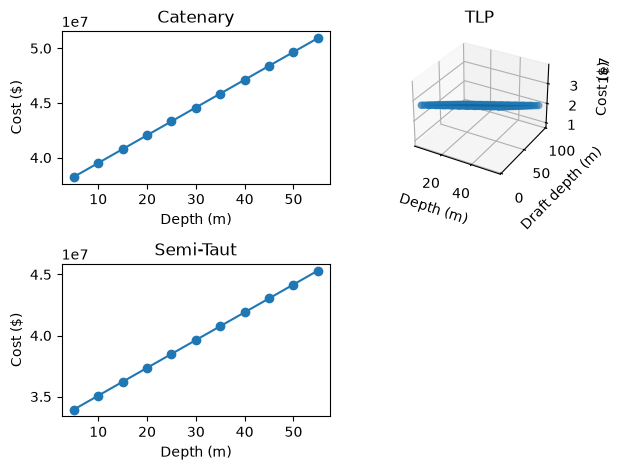

In [8]:
design_phase = "MooringSystemDesign"
results = {
    "mooring_system_system_cost": lambda run: run.design_results[
        "mooring_system"
    ]["system_cost"],
}

# Catenary mooring system
cost_catenary = CostFunction(
    config={
        "design_phases": [design_phase],
        "mooring_system_design": {"mooring_type": "Catenary"},
    },
    parameters={
        "site.depth": DEPTHS,
    },
    results=results,
)
cost_catenary.run()

# Tension Leg Platform (TLP) mooring system
cost_tlp = CostFunction(
    config={
        "design_phases": [design_phase],
        "mooring_system_design": {"mooring_type": "TLP"},
    },
    parameters={
        "site.depth": DEPTHS,
        "mooring_system_design.draft_depth": list(
            range(5, 100, 5)
        ),  # Draft depth 5-100 meters
    },
    results=results,
)
cost_tlp.run()

# Semi-taut mooring system
cost_semitaut = CostFunction(
    config={
        "design_phases": [design_phase],
        "mooring_system_design": {"mooring_type": "SemiTaut"},
    },
    parameters={
        "site.depth": DEPTHS,
    },
    results=results,
)
cost_semitaut.run()

## Fit the data to a curve
cost_catenary.linear_1d()
cost_tlp.linear_2d()
cost_semitaut.linear_1d()

## Plot the ORBIT data and curve fits
fig = plt.figure()

ax = fig.add_subplot(2, 2, 1)
ax.set_title("Catenary")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cost ($)")
cost_catenary.plot(ax, plot_data=True)
cost_catenary.plot(ax, plot_curves=["linear_1d"])

ax = fig.add_subplot(2, 2, 2, projection="3d")
ax.set_title("TLP")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Draft depth (m)")
ax.set_zlabel("Cost ($)")
cost_tlp.plot(ax, plot_data=True)
cost_tlp.plot(ax, plot_curves=["linear_2d"])

ax = fig.add_subplot(2, 2, 3)
ax.set_title("Semi-Taut")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cost ($)")
cost_semitaut.plot(ax, plot_data=True)
cost_semitaut.plot(ax, plot_curves=["linear_1d"])

cost_catenary.export(example_dir / "configs/mooring_system.yaml", "catenary")
cost_tlp.export(example_dir / "configs/mooring_system.yaml", "tlp")
cost_semitaut.export(example_dir / "configs/mooring_system.yaml", "semitaut")

## Array System

The array system cost is entirely dependent on the cable length.
The cable length is a function of some fixed plant parameters and the following spatially
dependent parameters:
- water depth
- touchdown distance
- floating cable depth

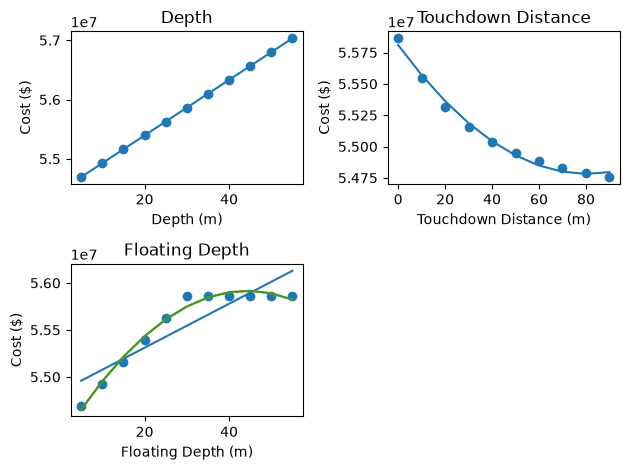

In [9]:
# First plot cost as a function of depth, touchdown_distance, and floating_cable_depth to get a
# sense for the 1d relationships

design_phase = "ArraySystemDesign"
results = {
    "array_system_system_cost": lambda run: run.design_results["array_system"][
        "system_cost"
    ],
}

# Water depth
cost_depth = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "site.depth": DEPTHS,
    },
    results=results,
)
cost_depth.run()

# Touchdown distance
cost_touchdown_distance = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "array_system_design.touchdown_distance": list(range(0, 100, 10)),
    },
    results=results,
)
cost_touchdown_distance.run()

# Floating cable depth
cost_cable_depth = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "array_system_design.floating_cable_depth": DEPTHS,
    },
    results=results,
)
cost_cable_depth.run()

cost_depth.linear_1d()
cost_touchdown_distance.quadratic_1d()
cost_cable_depth.linear_1d()
cost_cable_depth.quadratic_1d()
cost_cable_depth.poly3_1d()

fig = plt.figure()
ax = fig.add_subplot(2, 2, 1)
ax.set_title("Depth")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cost ($)")
cost_depth.plot(ax, plot_data=True)
cost_depth.plot(ax, plot_curves=["linear_1d"])

ax = fig.add_subplot(2, 2, 2)
ax.set_title("Touchdown Distance")
ax.set_xlabel("Touchdown Distance (m)")
ax.set_ylabel("Cost ($)")
cost_touchdown_distance.plot(ax, plot_data=True)
cost_touchdown_distance.plot(ax, plot_curves=["quadratic_1d"])

ax = fig.add_subplot(2, 2, 3)
ax.set_title("Floating Depth")
ax.set_xlabel("Floating Depth (m)")
ax.set_ylabel("Cost ($)")
cost_cable_depth.plot(ax, plot_data=True)
cost_cable_depth.plot(
    ax, plot_curves=["linear_1d", "quadratic_1d", "poly3_1d"]
)

In [10]:
# Then create functions of two variables.
# NOTE: The parameterization and plotting are split in two blocks since the ORBIT model takes
# some time to run.

design_phase = "ArraySystemDesign"
results = {
    "array_system_system_cost": lambda run: run.design_results["array_system"][
        "system_cost"
    ],
}

# Water depth vs touchdown distance
cost_depth_touchdown_distance = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "site.depth": DEPTHS,
        "array_system_design.touchdown_distance": list(range(0, 100, 10)),
    },
    results=results,
)
cost_depth_touchdown_distance.run()

# Water depth vs cable depth
cost_depth_cabledepth = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "site.depth": DEPTHS,
        "array_system_design.floating_cable_depth": DEPTHS,
    },
    results=results,
)
cost_depth_cabledepth.run()

# Touchdown distance vs cable depth
cost_touchdown_cabledepth = CostFunction(
    config={
        "design_phases": [design_phase],
    },
    parameters={
        "array_system_design.floating_cable_depth": DEPTHS,
        "array_system_design.touchdown_distance": list(range(0, 100, 10)),
    },
    results=results,
)
cost_touchdown_cabledepth.run()

The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.RuntimeWarning: /Users/rhammond/GitHub/Public/ORBIT/ORBIT/phases/design/_cables.py:391
overflow encountered in cosh


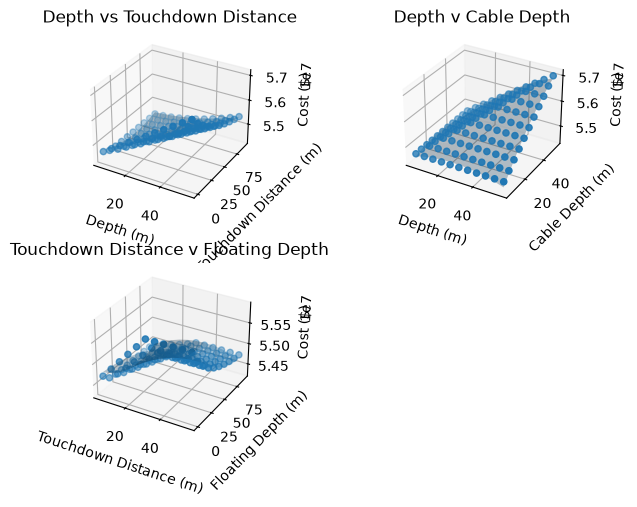

In [11]:
# NOTE: The parameterization and plotting are split in two blocks since the ORBIT model takes
# some time to run.

cost_depth_touchdown_distance.quadratic_2d()
cost_depth_cabledepth.quadratic_2d()
cost_touchdown_cabledepth.quadratic_2d()

fig = plt.figure()
ax = fig.add_subplot(2, 2, 1, projection="3d")
ax.set_title("Depth vs Touchdown Distance")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Touchdown Distance (m)")
ax.set_zlabel("Cost ($)")
cost_depth_touchdown_distance.plot(ax, plot_data=True)
cost_depth_touchdown_distance.plot(ax, plot_curves=["quadratic_2d"])

ax = fig.add_subplot(2, 2, 2, projection="3d")
ax.set_title("Depth v Cable Depth")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cable Depth (m)")
ax.set_zlabel("Cost ($)")
cost_depth_cabledepth.plot(ax, plot_data=True)
cost_depth_cabledepth.plot(ax, plot_curves=["quadratic_2d"])

ax = fig.add_subplot(2, 2, 3, projection="3d")
ax.set_title("Touchdown Distance v Floating Depth")
ax.set_xlabel("Touchdown Distance (m)")
ax.set_ylabel("Floating Depth (m)")
ax.set_zlabel("Cost ($)")
cost_touchdown_cabledepth.plot(ax, plot_data=True)
cost_touchdown_cabledepth.plot(ax, plot_curves=["quadratic_2d"])

In [12]:
cost_touchdown_cabledepth.export(
    example_dir / "configs/array_system.yaml", "floating"
)

{'floating': '54571434.2 * floating_cable_depth**2 + 45993.5 * floating_cable_depth * touchdown_distance + -15220.9 * touchdown_distance**2 + -190.8 * floating_cable_depth + -406.1 * touchdown_distance + 136.2'}


## Export System

This block creates a cost model for systems with high voltage alternating current (HVAC) and
high voltage direct current (HVDC) cables.

Independent variables:
- site.distance_to_landfall
- Depth

{'floating_hvac': '3001.8 * depth + 3001804.0 * dist_s_to_l + 9005412.0'}
{'floating_hvdc': '900.0 * depth + 900000.0 * dist_s_to_l + 2700000.0'}


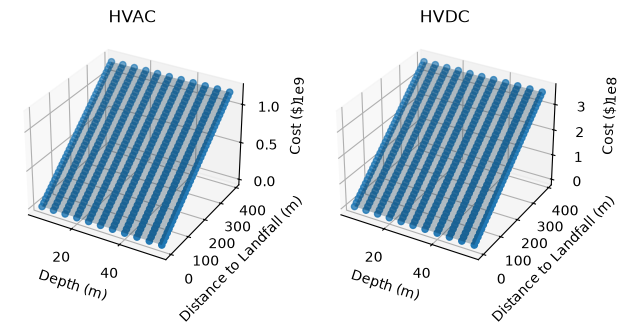

In [13]:
design_phase = "ExportSystemDesign"
results = {
    "export_system_system_cost": lambda run: run.design_results[
        "export_system"
    ]["system_cost"],
}

## Run ORBIT for each hvac and hvdc export system types

cost_hvac = CostFunction(
    config={
        "design_phases": [design_phase],
        "export_system_design": {"cables": "XLPE_1000mm_220kV"},
    },
    parameters={
        "site.depth": DEPTHS,
        "site.distance_to_landfall": list(range(0, 400, 10)),
    },
    results=results,
)
cost_hvac.run()

cost_hvdc = CostFunction(
    config={
        "design_phases": [design_phase],
        "export_system_design": {"cables": "HVDC_2000mm_320kV"},
    },
    parameters={
        "site.depth": DEPTHS,
        "site.distance_to_landfall": list(range(0, 400, 10)),
    },
    results=results,
)
cost_hvdc.run()

cost_hvac.linear_2d()
cost_hvdc.linear_2d()

## Plot the ORBIT data and curve fits

fig = plt.figure()

ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.set_title("HVAC")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Distance to Landfall (m)")
ax.set_zlabel("Cost ($)")
cost_hvac.plot(ax, plot_data=True)
cost_hvac.plot(ax, plot_curves=["linear_2d"])

ax = fig.add_subplot(1, 2, 2, projection="3d")
ax.set_title("HVDC")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Distance to Landfall (m)")
ax.set_zlabel("Cost ($)")
cost_hvdc.plot(ax, plot_data=True)
cost_hvdc.plot(ax, plot_curves=["linear_2d"])


multiline_comment = "\n# ".join(
    [
        "The floating HVAC mooring system is ",
        "special because it's the only one that ",
        "is like it is.",
    ]
)
cost_hvac.export(
    example_dir / "configs/export_system.yaml",
    "floating_hvac",
    comments=multiline_comment,
)

singleline_comment = "HVDC export system"
cost_hvdc.export(
    example_dir / "configs/export_system.yaml",
    "floating_hvdc",
    comments=singleline_comment,
)

## Offshore Floating Substation

This component is not a function of a spatially varying parameter, but it is included to complete
the export of the capex breakdown components.

{'oss_substructure': '0.0 * depth + 1820400.0'}


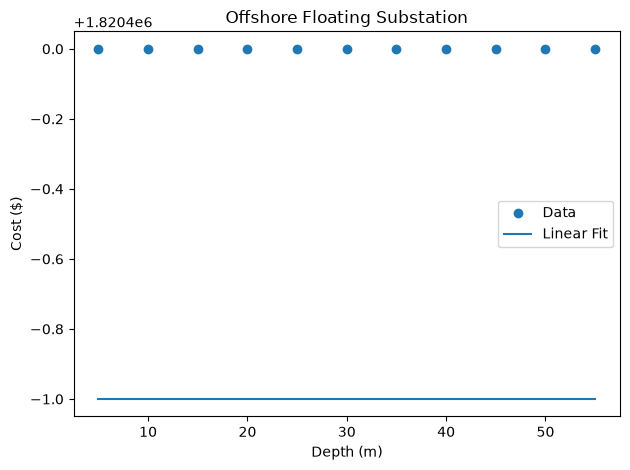

In [14]:
cost_function = CostFunction(
    config={"design_phases": ["OffshoreFloatingSubstationDesign"]},
    parameters={
        "site.depth": DEPTHS,
    },
    results={
        "offshore_substation_substructure": lambda run: run.design_results[
            "offshore_substation_substructure"
        ]["unit_cost"],
    },
)
cost_function.run()

cost_function.linear_1d()

fig = plt.figure()
ax = fig.add_subplot()
ax.set_title("Offshore Floating Substation")
ax.set_xlabel("Depth (m)")
ax.set_ylabel("Cost ($)")
cost_function.plot(ax, plot_data=True)
cost_function.plot(ax, plot_curves=["linear_1d"])
ax.legend()

cost_function.export(example_dir / "configs/oss.yaml", "oss_substructure")